# Proyecto -- Timeseries Forecasting
## M3BEDU

- **Objetivo**: De una serie de tiempo, en este caso las ventas de un negocio, haremos predicciones a futuro sólo *en base a tendencias y periodicidad histórica* (métodos autoregresivos).

- **Herramientas**: Usaremos principalmente StatModels y sus distintas liberías para análisis y modelación de series de tiempo.

- **Basado en**:
https://towardsdatascience.com/predict-time-stamped-sales-in-python-1914292461ad
https://github.com/srees1988/sarima-in-py/blob/master/SARIMA.ipynb

- **Dataset**: De Kaggle via
https://github.com/srees1988/sarima-in-py/blob/master/online_retail.xlsx

In [149]:
#Data Preprocessing:
import glob
import os as os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#%matplotlib inline
#from matplotlib import dates
#import warnings
#warnings.simplefilter("ignore")

#Data Analysis, Model Selection and Forecasting:
import statsmodels as st
import pmdarima
import sklearn.metrics

In [2]:
#Setup dir and look at it.
os.chdir(r"/Users/iheredia/OneDrive - CINVESTAV/DataspellProjects/pythonc310Project/forecast")
for file in glob.glob('./*'):
    print(file)

./README.md
./online_retail.xlsx
./Forecast_sales.ipynb


In [3]:
#Load data and explore:
df = pd.read_excel("online_retail.xlsx", engine='openpyxl') #,parse_dates = True
df.head(5)

,Month,Sales
0,1992-01-01,3459
1,1992-02-01,3458
2,1992-03-01,4002
3,1992-04-01,4564
4,1992-05-01,4221


In [4]:
df.tail(5)

,Month,Sales
320,2018-09-01,12396
321,2018-10-01,13914
322,2018-11-01,14174
323,2018-12-01,15504
324,2019-01-01,10718


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Month   325 non-null    datetime64[ns]
 1   Sales   325 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 5.2 KB


In [6]:
df.describe()

,Month,Sales
count,325,325.000000
mean,2005-07-01 13:35:15.692307712,7886.400000
min,1992-01-01 00:00:00,3031.000000
25%,1998-10-01 00:00:00,5231.000000
50%,2005-07-01 00:00:00,7481.000000
75%,2012-04-01 00:00:00,9977.000000
max,2019-01-01 00:00:00,15504.000000
std,NaN,2914.269061


In [7]:
# Date is already a datetime64[ns] with correct formar, so no need to convert.
#df["Month"]  =  pd.to_datetime(df["Month"], format='%Y-%m-%d')
#df.info()

In [8]:
#Dropping NA's (just in case!):
df = df.dropna()

In [9]:
#Set the Datetime field as the index field and
df.set_index("Month",inplace=True)

In [10]:
# Set index frequency: https://pandas.pydata.org/docs/user_guide/timeseries.html#timeseries-offset-aliases
# Will use calendar month begin (MS)
print(df.index.freq)
df.index.freq = 'MS'
print(df.index.freq)

None
<MonthBegin>


In [11]:
# Check...
df.tail(2)

,Sales
Month,
2018-12-01,15504
2019-01-01,10718


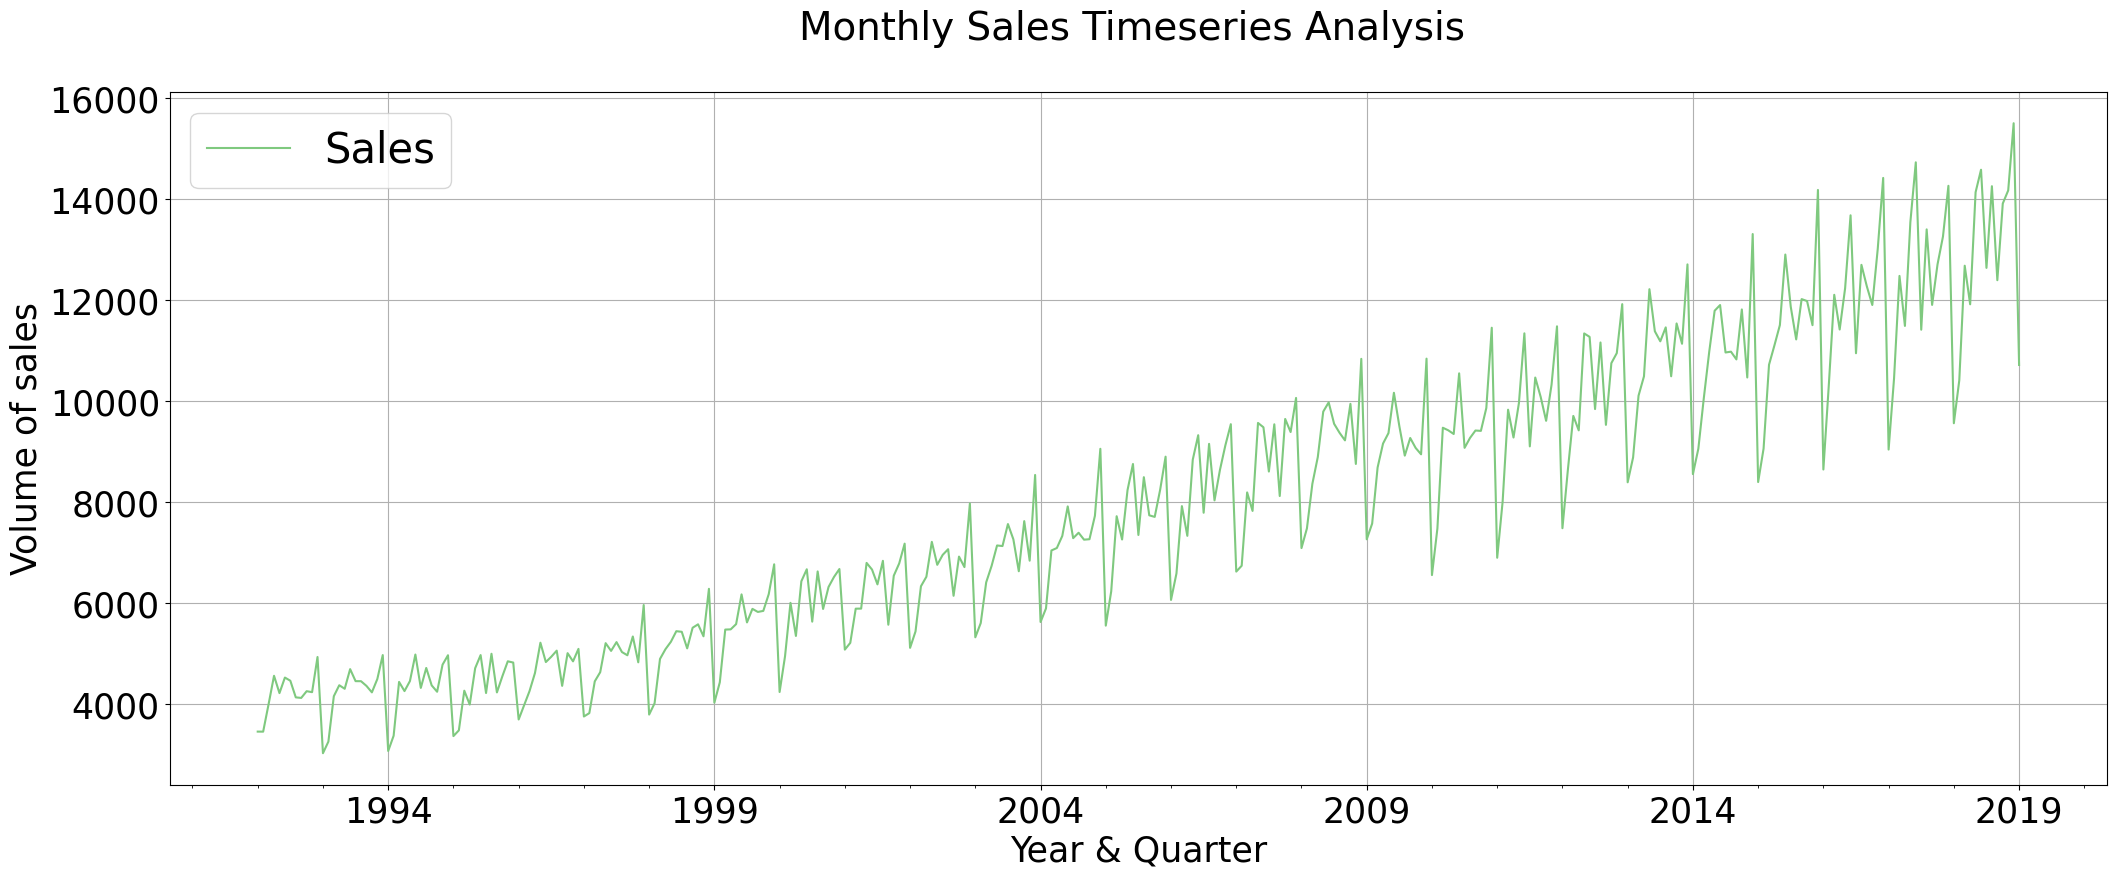

In [12]:
#Plot Timeseries:
ax =  df['Sales'].plot(legend =True, table = False, grid = True, subplots = False, figsize =(25,9), fontsize = 25, colormap = 'Accent', linestyle='-', stacked=False)
plt.ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.title('Monthly Sales Timeseries Analysis \n',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
plt.legend(loc='upper left', fontsize = 30)
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")
ax.autoscale(enable=True, axis='x', tight=False)

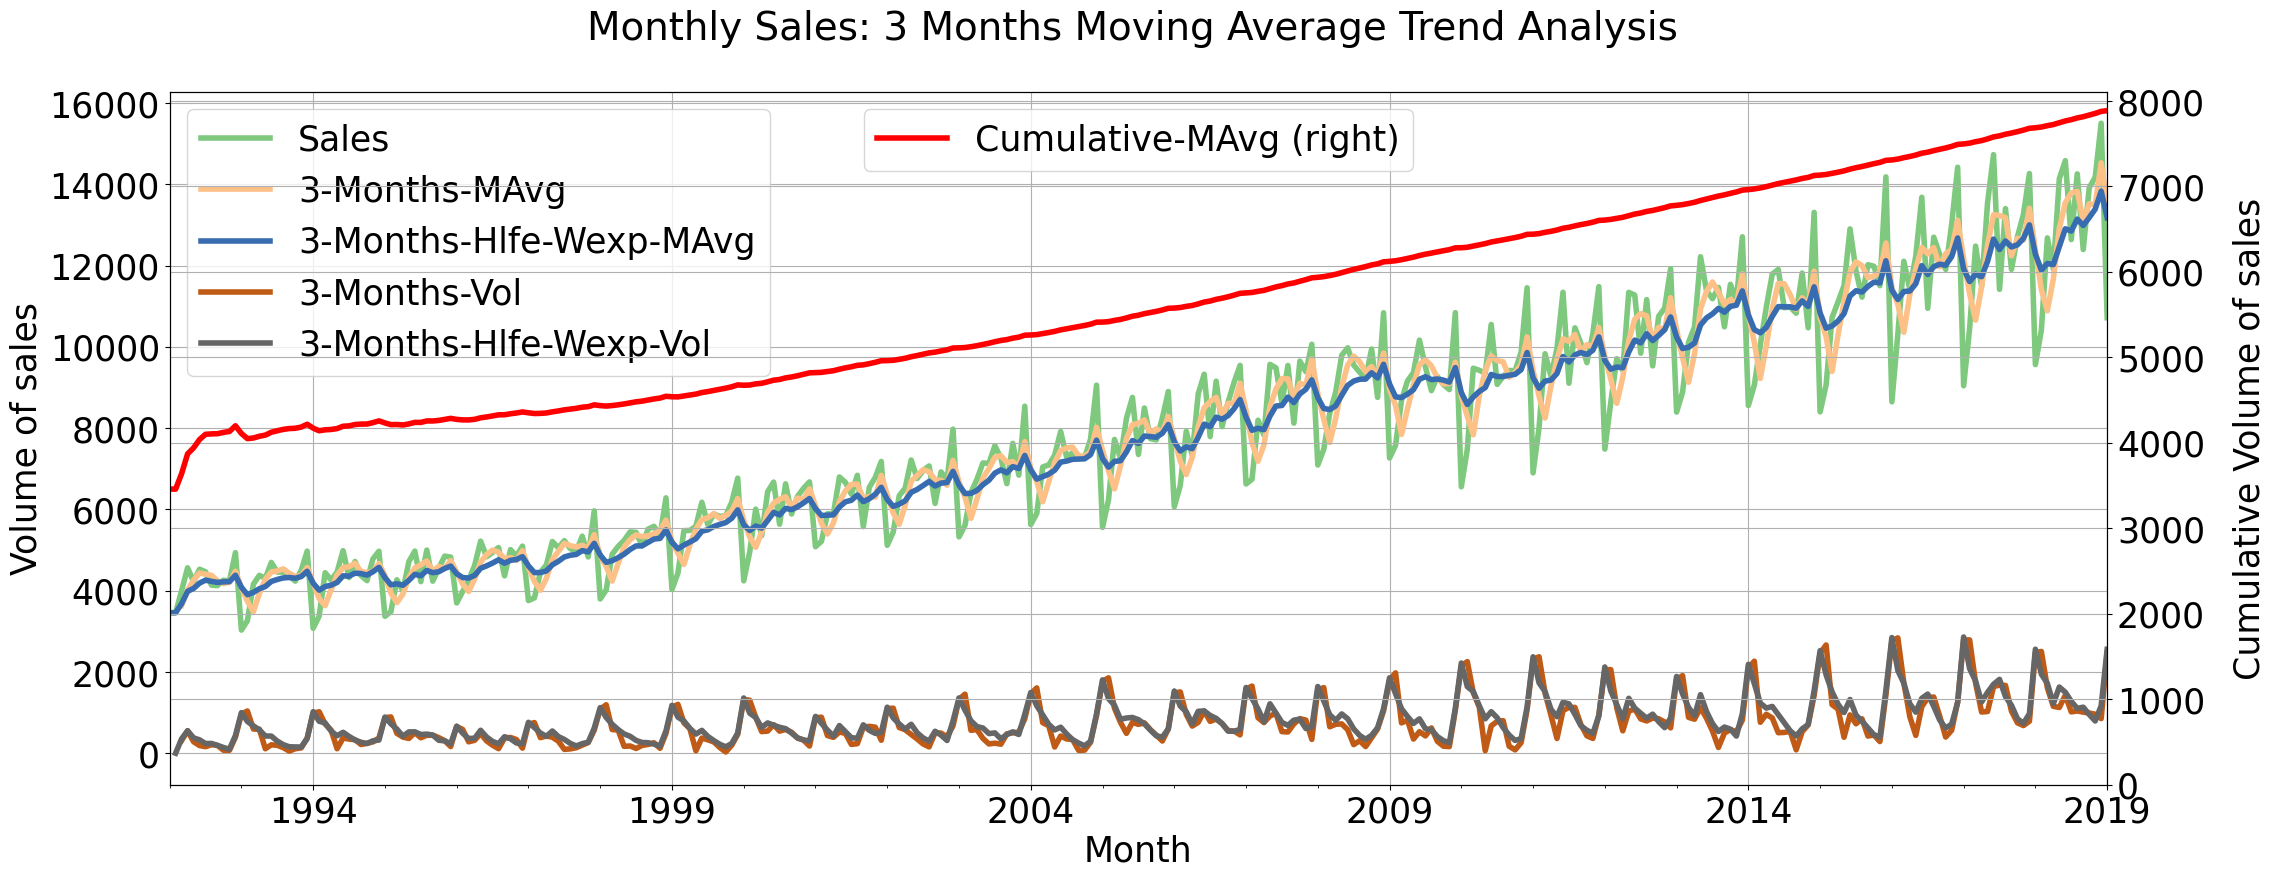

In [13]:
# Simple Moving Average Trend Analysis
#   --> help to identify areas of support ad resistance.
#   --> filters out random noise / smoothes out fluctuations.

# Windowing (group) every 3 months to smooth series and find volatility.
df["3-Months-MAvg"] = df["Sales"].rolling(window=3).mean()
df['3-Months-Vol'] = df['Sales'].rolling(window=3).std()

# Also try exponential weighted moving average:
df['3-Months-Hlfe-Wexp-MAvg'] = df["Sales"].ewm(halflife="90 days", times=df.index).mean()
df['3-Months-Hlfe-Wexp-Vol'] = df["Sales"].ewm(halflife="90 days", times=df.index).std()

# And cumulative (all previous points w/o weighting) moving average
df['Cumulative-MAvg'] = df['Sales'].expanding().mean()

# Prepare axes:
plt.figure(figsize=(25,9))
plt.title('Monthly Sales: 3 Months Moving Average Trend Analysis \n',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
ax = plt.gca() #get current axis
ax.set_xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")

# Plot moving averages and volatility:
ax1 =  df[['Sales', '3-Months-MAvg','3-Months-Hlfe-Wexp-MAvg','3-Months-Vol','3-Months-Hlfe-Wexp-Vol']].plot(fontsize = 25, table = False, grid = True, subplots = False, colormap = 'Accent', linestyle='-', stacked=False, linewidth = 4, ax=ax)

# Plot cumulative average
ax2 = df[['Cumulative-MAvg']].plot(fontsize = 25, table = False, grid = True, subplots = False, linestyle='-', stacked=False, linewidth = 4, color='r', ax=ax, secondary_y = True)
ax1.set_ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
ax2.set_ylabel('Cumulative Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif", labelpad=20)
ax2.set_ylim(ymin=0)

ax1.legend(loc="upper left", fontsize = 25)
ax2.legend(loc="upper center", fontsize = 25)
plt.xticks(rotation=0, horizontalalignment="center")
#plt.yticks(rotation=0, horizontalalignment="right")
ax.autoscale(enable=True, axis='x', tight=True)

From the rolling 3-months moving averages trendlines:
 --> Sales trends up around the mid of every quarter
 --> Band of resistance towards the end of the very same quarter.
 --> Band of support occurs before the wave of resistance in every quarter.

From the volatility:
 --> Slightly increases with time, hinting non-stationarity.

From Cumulative average:
 --> Average across history, lows and highs.
 --> Slightly increase with time, so company grows slowly but constant.

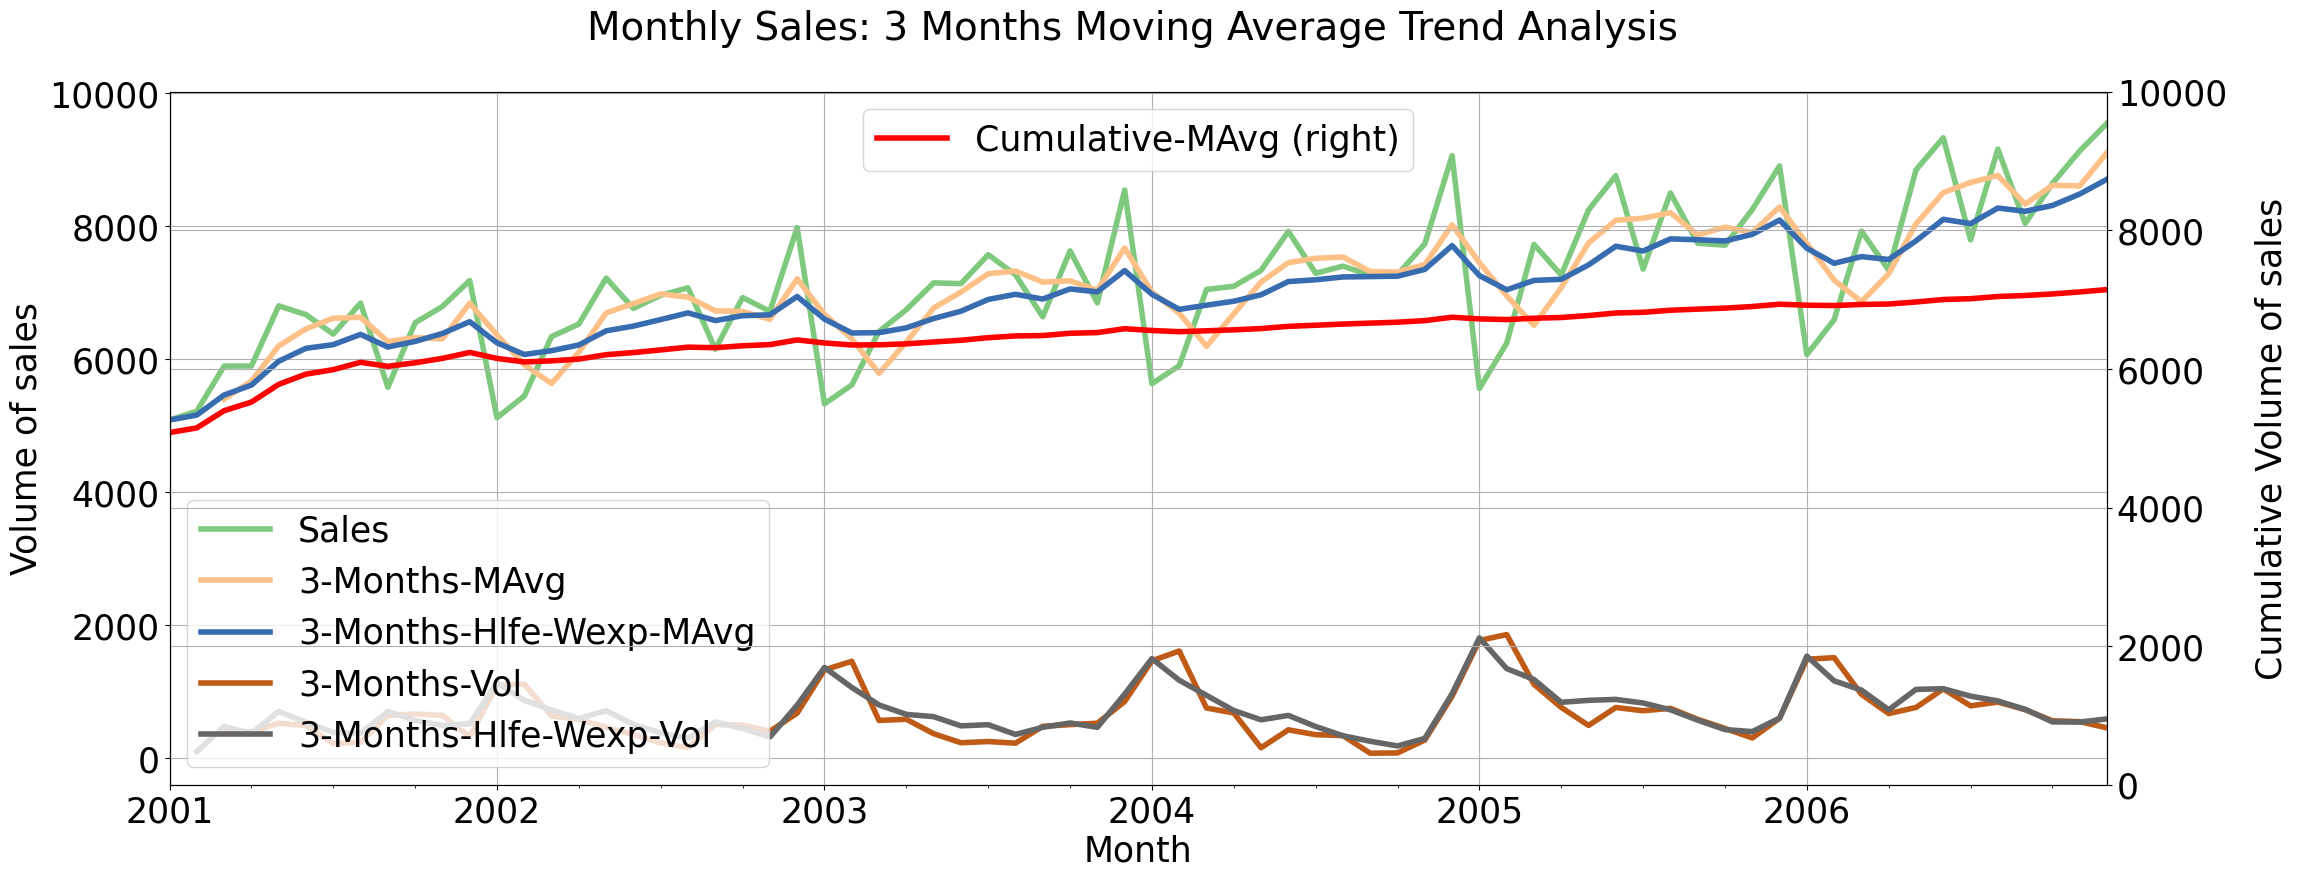

In [64]:
# Let's repeat the plot in a smaller interval to make the previous observations
# more obvious.
selector = (df.index.year>=2001) & (df.index.year<2007)
df_small = df[selector].copy()

df_small["3-Months-MAvg"] = df_small["Sales"].rolling(window=3).mean()
df_small['3-Months-Vol'] = df_small['Sales'].rolling(window=3).std()
df_small['3-Months-Hlfe-Wexp-MAvg'] = df_small["Sales"].ewm(halflife="90 days", times=df_small.index).mean()
df_small['3-Months-Hlfe-Wexp-Vol'] = df_small["Sales"].ewm(halflife="90 days", times=df_small.index).std()
df_small['Cumulative-MAvg'] = df_small['Sales'].expanding().mean()

plt.figure(figsize=(25,9))
plt.title('Monthly Sales: 3 Months Moving Average Trend Analysis \n',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
ax = plt.gca() #get current axis
ax.set_xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
ax1 = df_small[['Sales', '3-Months-MAvg','3-Months-Hlfe-Wexp-MAvg','3-Months-Vol','3-Months-Hlfe-Wexp-Vol']].plot(fontsize = 25, table = False, grid = True, subplots = False, colormap = 'Accent', linestyle='-', stacked=False, linewidth = 4, ax=ax)
ax2 = df_small[['Cumulative-MAvg']].plot(fontsize = 25, table = False, grid = True, subplots = False, linestyle='-', stacked=False, linewidth = 4, color='r', ax=ax, secondary_y = True)
ax1.set_ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
ax2.set_ylabel('Cumulative Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif", labelpad=20)
ax2.set_ylim(ymin=0,ymax=10000)
ax1.legend(loc="lower left", fontsize = 25)
ax2.legend(loc="upper center", fontsize = 25)
plt.xticks(rotation=0, horizontalalignment="center")
ax.autoscale(enable=True, axis='x', tight=True)

The Hodrick–Prescott filter (also known as Hodrick–Prescott decomposition) is used in macroeconomics, especially in real business cycle theory, to remove the cyclical component of a time series from raw data.

It is used to obtain a smoothed-curve representation of a time series, one that is more sensitive to long-term than to short-term fluctuations.

The adjustment of the sensitivity of the trend to short-term fluctuations is achieved by modifying a multiplier \lambda .

It is a special case of a smoothing spline.

If x_t is the original series,
  y_t = ln(x_t) = tau_t (trend comp.) + c_t (cyclical comp.) + eps_t (error comp.)
  --> To isolate trend component, find tau_t that minimizes sum_t(y_t - tau_t) ==> penalizes cyclical component.
    --> To isolate cyclical component, tau_t is also required to minimize lambda * [(tau_t+1 + tau_t) + (tau_t - tau_t-1) ]^2 ==> lambda gauges the penalization on the increase of the trend component.
       --> lambda ~ 1600 for quarterly data. In practice, lambda ~ 100 for yearly data, and ~ 14,400 for monthly data.

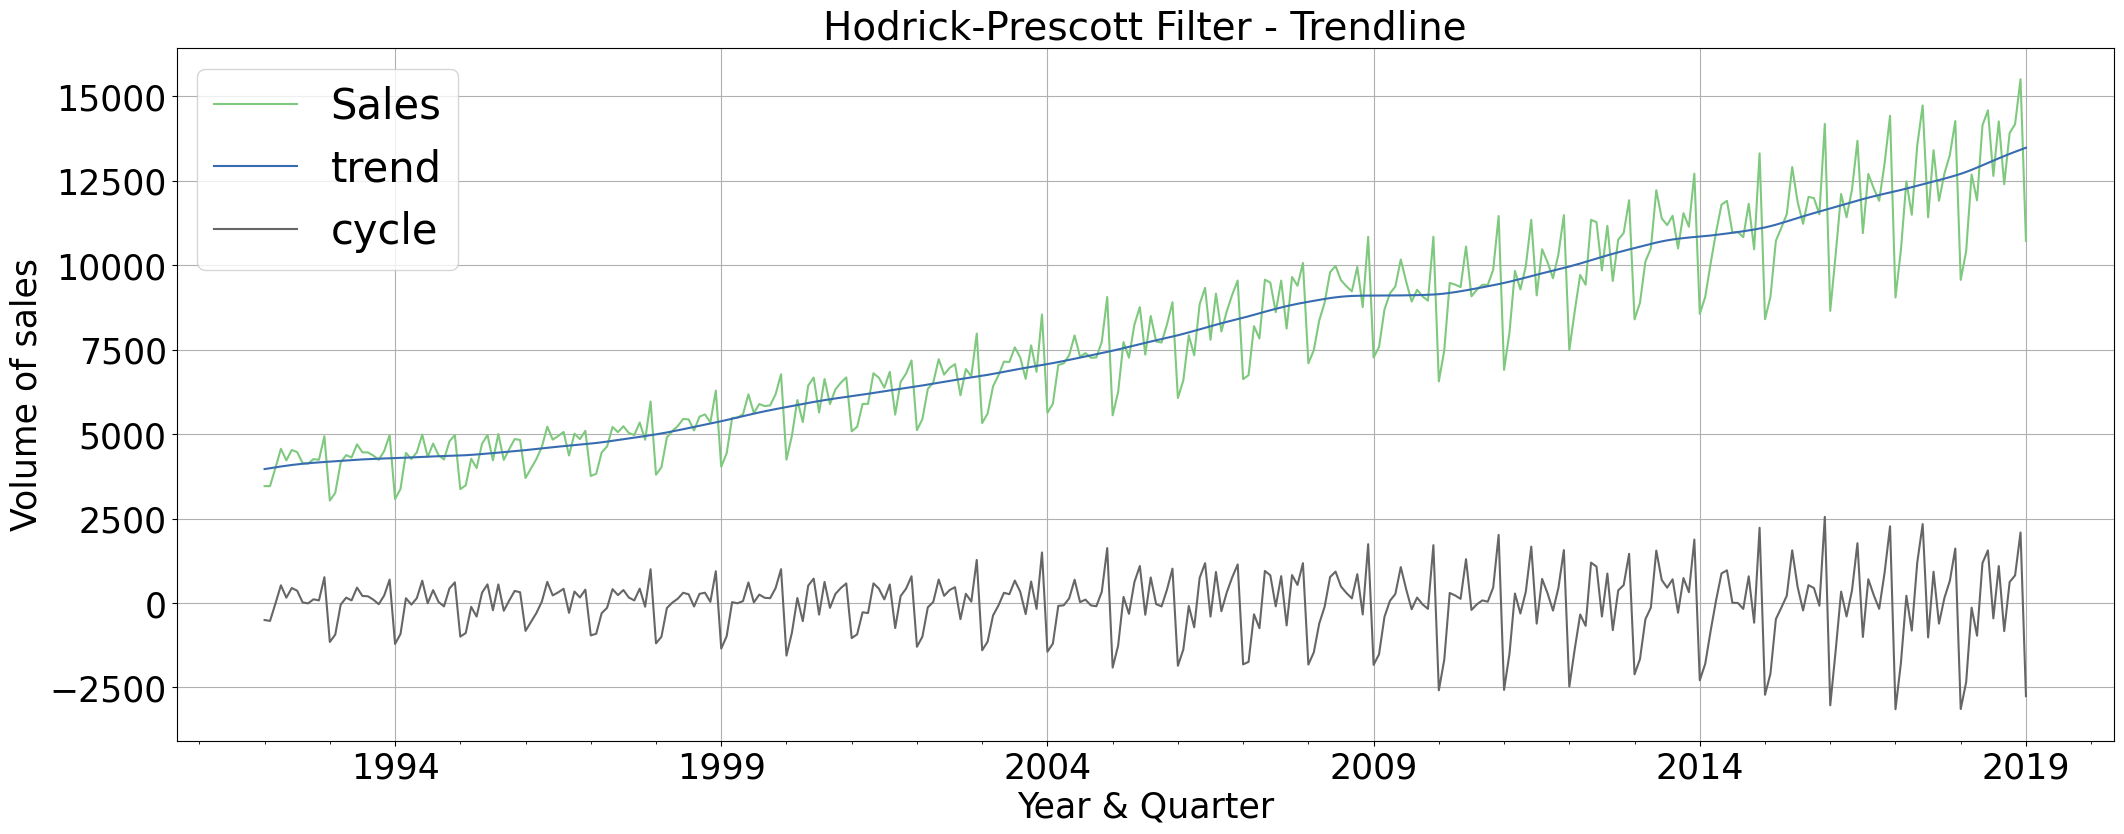

In [15]:
# Hodrick-Prescott Filter:

# Extract cyclical and trend components:
sales_cycle, sales_trend = st.tsa.filters.hp_filter.hpfilter(df["Sales"], lamb = 1600)
df["cycle"] = sales_cycle
df["trend"] = sales_trend

# Plot timeseries and components:
ax =  df[["Sales","trend","cycle"]].plot(legend =True, table = False, grid = True, subplots = False, figsize =(25,9), fontsize = 25, colormap = 'Accent', linestyle='-', stacked=False)
plt.ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.title('Hodrick-Prescott Filter - Trendline',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
plt.legend(loc='upper left', fontsize = 30)
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")
ax.autoscale(enable=True, axis='x', tight=False)


The trendline confirms an overall growth pattern at a non-linear rate over the course of time.

Now, a more serious analysis would separate a time-series in:
   - three systematic components (can be modeled): level, trend, seasonality.
   - one non-systematic component:  noise/error/residual.

Level: The average value in the series --> Really, just the average.
Trend: The increasing or decreasing value in the series --> hpfilter --> in this context, trend can include "a cyclical", but not seasonal (repetitive) component.
Seasonality: The repeating short-term cycle in the series --> really is the repetitive component --> ETS decomposition.
Noise: The random variation in the series. --> ETS decomposition.

Let's isolate systematic & non-systematic components.

Since sales increase seems to be non-linear, "a 'multiplicative' model is appropiate".
 --> Otherwise, when seasonality and trend components are constant over time, apply "an 'additive' model".

ETS (Error-Trend-Seasonality) decompsition by: https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.seasonal_decompose.html
 --> This is a naive decomposition. More sophisticated methods should be preferred.
 --> The additive model is Y[t] = T[t] + S[t] + e[t]
 --> The multiplicative model is Y[t] = T[t] * S[t] * e[t]

The results are obtained by first estimating the trend by applying a convolution filter to the data. The trend is then removed from the series and the average of this de-trended series for each period is the returned seasonal component.



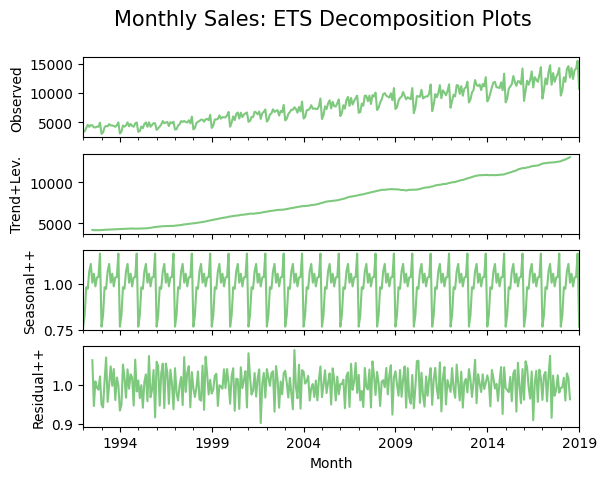

In [72]:
result = st.tsa.seasonal.seasonal_decompose(df["Sales"]
                            , model = "multiplicative")
fig, axes = plt.subplots(4, 1, sharex=True)
fig.suptitle("Monthly Sales: ETS Decomposition Plots",horizontalalignment="center", fontstyle = "normal", fontsize = "15", fontfamily = "sans-serif")
result.observed.plot(ax=axes[0], legend=False, colormap = 'Accent')
axes[0].set_ylabel('Observed')
result.trend.plot(ax=axes[1], legend=False, colormap = 'Accent')
axes[1].set_ylabel('Trend+Lev.')
result.seasonal.plot(ax=axes[2], legend=False, colormap = 'Accent')
axes[2].set_ylabel('Seasonal++')
result.resid.plot(ax=axes[3], legend=False, colormap = 'Accent')
axes[3].set_ylabel('Residual++')
ax.autoscale(enable=True, axis='x', tight=False)

Let's check seasonality by taking lags, which are linear regressions between x_t and x_t-k , where k = 1,2,3,... If there is a period, the correlation should be periodic.

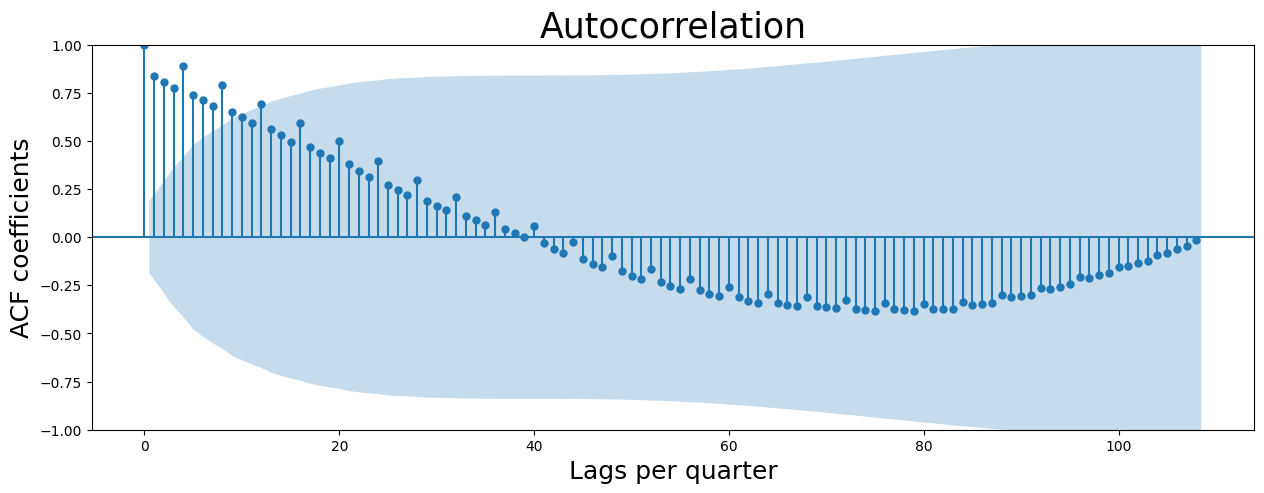

In [86]:
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(111)
st.graphics.tsaplots.plot_acf(df.asfreq(freq ='3MS')["Sales"],lags=108, alpha=0.05,ax=ax) #(df.shape[0]-1)
plt.ylabel('ACF coefficients',horizontalalignment="center",fontstyle = "normal", fontsize = 18, fontfamily = "sans-serif")
plt.xlabel('Lags per quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 18, fontfamily = "sans-serif")
plt.title('Autocorrelation',horizontalalignment="center", fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
ax.autoscale(enable=True, axis='x', tight=False)

Correlation is lost every ~40*4/12 ~ 13 years, is periodic every year, and is significant for ~ 2 years.

Partial Auto Correlation (PACF) Plots:

* A partial autocorrelation is the amount of correlation between a variable and a lag of itself that is not explained by correlations at all lower-order-lags.
  - Partial auto-correlation between x_t and x_t-k removes the contribution to the correlation due to other lags x_t-l, for l = 1,2,..,k-1.
 https://en.wikipedia.org/wiki/Partial_autocorrelation_function
    --> That is, the autocorrelations are significant for a large number of lags--but perhaps the autocorrelations at lags 2 and above are merely due to the propagation of the autocorrelation at lag 1. This can be confirmed by the PACF plot.

* As we will see later, for an "Autoregressive" model (AR), one examines the PACF plots to find the lag after which the partial auto-correlations are all within the confidence interval. This lag is determined to likely be the AR model's order.

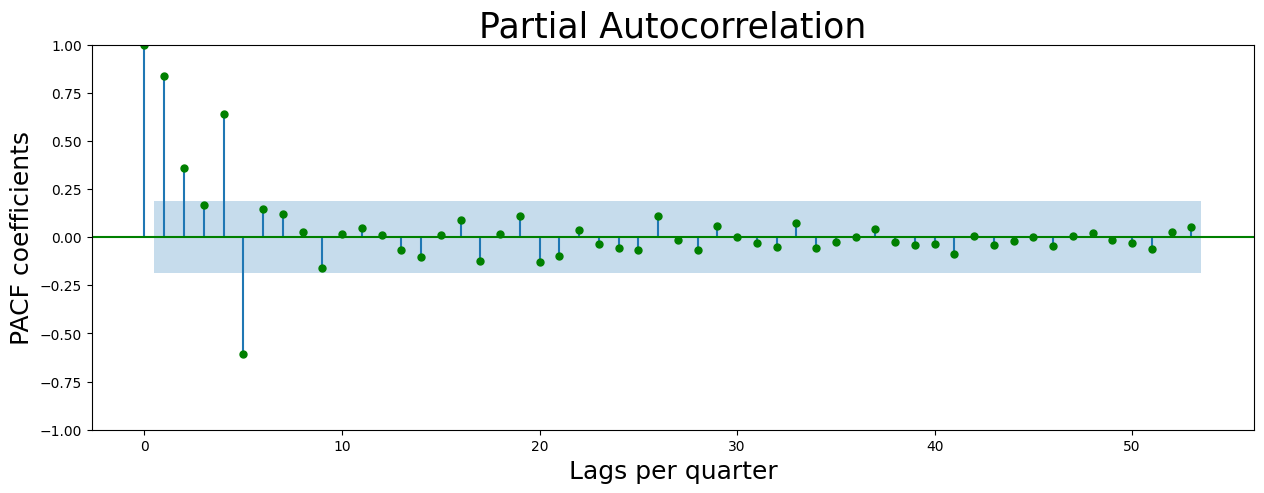

In [87]:
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(111)
st.graphics.tsaplots.plot_pacf(df.asfreq(freq ='3MS')["Sales"].dropna(), lags = np.arange(108/2), c='g', ax = ax);
plt.ylabel('PACF coefficients',horizontalalignment="center",fontstyle = "normal", fontsize = 18, fontfamily = "sans-serif")
plt.xlabel('Lags per quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 18, fontfamily = "sans-serif")
plt.title('Partial Autocorrelation',horizontalalignment="center", fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
ax.autoscale(enable=True, axis='x', tight=False)

* Definition: A stationary time series is one whose properties do not depend on the time at which the series is observed. Thus, time series with trends, or with seasonality, are not stationary — the trend and seasonality will affect the value of the time series at different times.
    - A white noise series is stationary — it does not matter when you observe it, it should look much the same at any point in time.
    - A time series with cyclic behaviour (but with no trend or seasonality) is stationary. This is because the cycles are not of a fixed length, so before we observe the series we cannot be sure where the peaks and troughs of the cycles will be.

* We will apply two (unit root) tests of NON-stationarity (https://otexts.com/fpp2/stationarity.html):
    1. The Augmented Dickey-Fuller test for stationarity takes null hypothesis H0 for a non-stationary timeseries. Alternate hypothesis H1 supports stationarity with a small p-value ( p<0.05 ).
    2. KPSS (Kwiatkowski-Phillips-Schmidt-Shin) Test results are directly opposite to that of the ADF test when it comes to interpreting the null and alternate hypothesis.

In [73]:
def adf_test(series,title=''):
    print(f'Augmented Dickey-Fuller Test: {title}')
    result = st.tsa.stattools.adfuller(series.dropna(),autolag='AIC') #.dropna() handles differenced data
    # fill first 4 indices
    labels = ['ADF test statistic','p-value','# lags used','# observations']
    out = pd.Series(result[0:4],index=labels)
    # fill 5th index by hand (critical values)
    for key,val in result[4].items():
        out[f'critical value ({key})']=val
    print(out.to_string())          # .to_string() removes the line "dtype: float64"
    if result[1] <= 0.05:
        print("Strong evidence against the null hypothesis")
        print("Reject the null hypothesis")
        print("Data has no unit root and is stationary")
    else:
        print("Weak evidence against the null hypothesis")
        print("Fail to reject the null hypothesis")
        print("Data has a unit root and is non-stationary")

def kpss_test(timeseries):
    print ('Results of KPSS Test:')
    kpsstest = st.tsa.stattools.kpss(timeseries, regression='c')
    kpss_output = pd.Series(kpsstest[0:3], index=
    ['Test Statistic','p-value','Lags Used'])
    for key,value in kpsstest[3].items():
        kpss_output['Critical Value (%s)'%key] = value
        print (kpss_output)


In [74]:
adf_test(df["Sales"], title = "Automated ADF Test for Stationarity")

Augmented Dickey-Fuller Test: Automated ADF Test for Stationarity
ADF test statistic        2.037405
p-value                   0.998720
# lags used              14.000000
# observations          310.000000
critical value (1%)      -3.451622
critical value (5%)      -2.870909
critical value (10%)     -2.571762
Weak evidence against the null hypothesis
Fail to reject the null hypothesis
Data has a unit root and is non-stationary


In [75]:
kpss_test(df["Sales"])

Results of KPSS Test:
Test Statistic           2.79443
p-value                  0.01000
Lags Used               11.00000
Critical Value (10%)     0.34700
dtype: float64
Test Statistic           2.79443
p-value                  0.01000
Lags Used               11.00000
Critical Value (10%)     0.34700
Critical Value (5%)      0.46300
dtype: float64
Test Statistic            2.79443
p-value                   0.01000
Lags Used                11.00000
Critical Value (10%)      0.34700
Critical Value (5%)       0.46300
Critical Value (2.5%)     0.57400
dtype: float64
Test Statistic            2.79443
p-value                   0.01000
Lags Used                11.00000
Critical Value (10%)      0.34700
Critical Value (5%)       0.46300
Critical Value (2.5%)     0.57400
Critical Value (1%)       0.73900
dtype: float64


/var/folders/px/hp6xtxyn7vl1zq8_k8x1f5kw0000gn/T/ipykernel_27764/1571344082.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpsstest = st.tsa.stattools.kpss(timeseries, regression='c')


* Forecasting requires looking for simpler (stationary) timeseries, which can be obtained from the original, for instance, by defining x_t' = x_t - x_t-1 = x_t - L(x_t) = (1-L)x_t or "FIRST DIFFERENTATION". (equivalent to daily returns of stocks).
    - If x_t' = eps = white noise, x_t' is a random walk (unpredictable).
    - "Nth-order differentiation" (e.g. x_t'' = x_t' - x_t-1') is shown to be x_t^(N) = (1-L)^N x_t.
    - Simple and seasonal differentiation can be both applied one after the other to make the timeseries stationary.

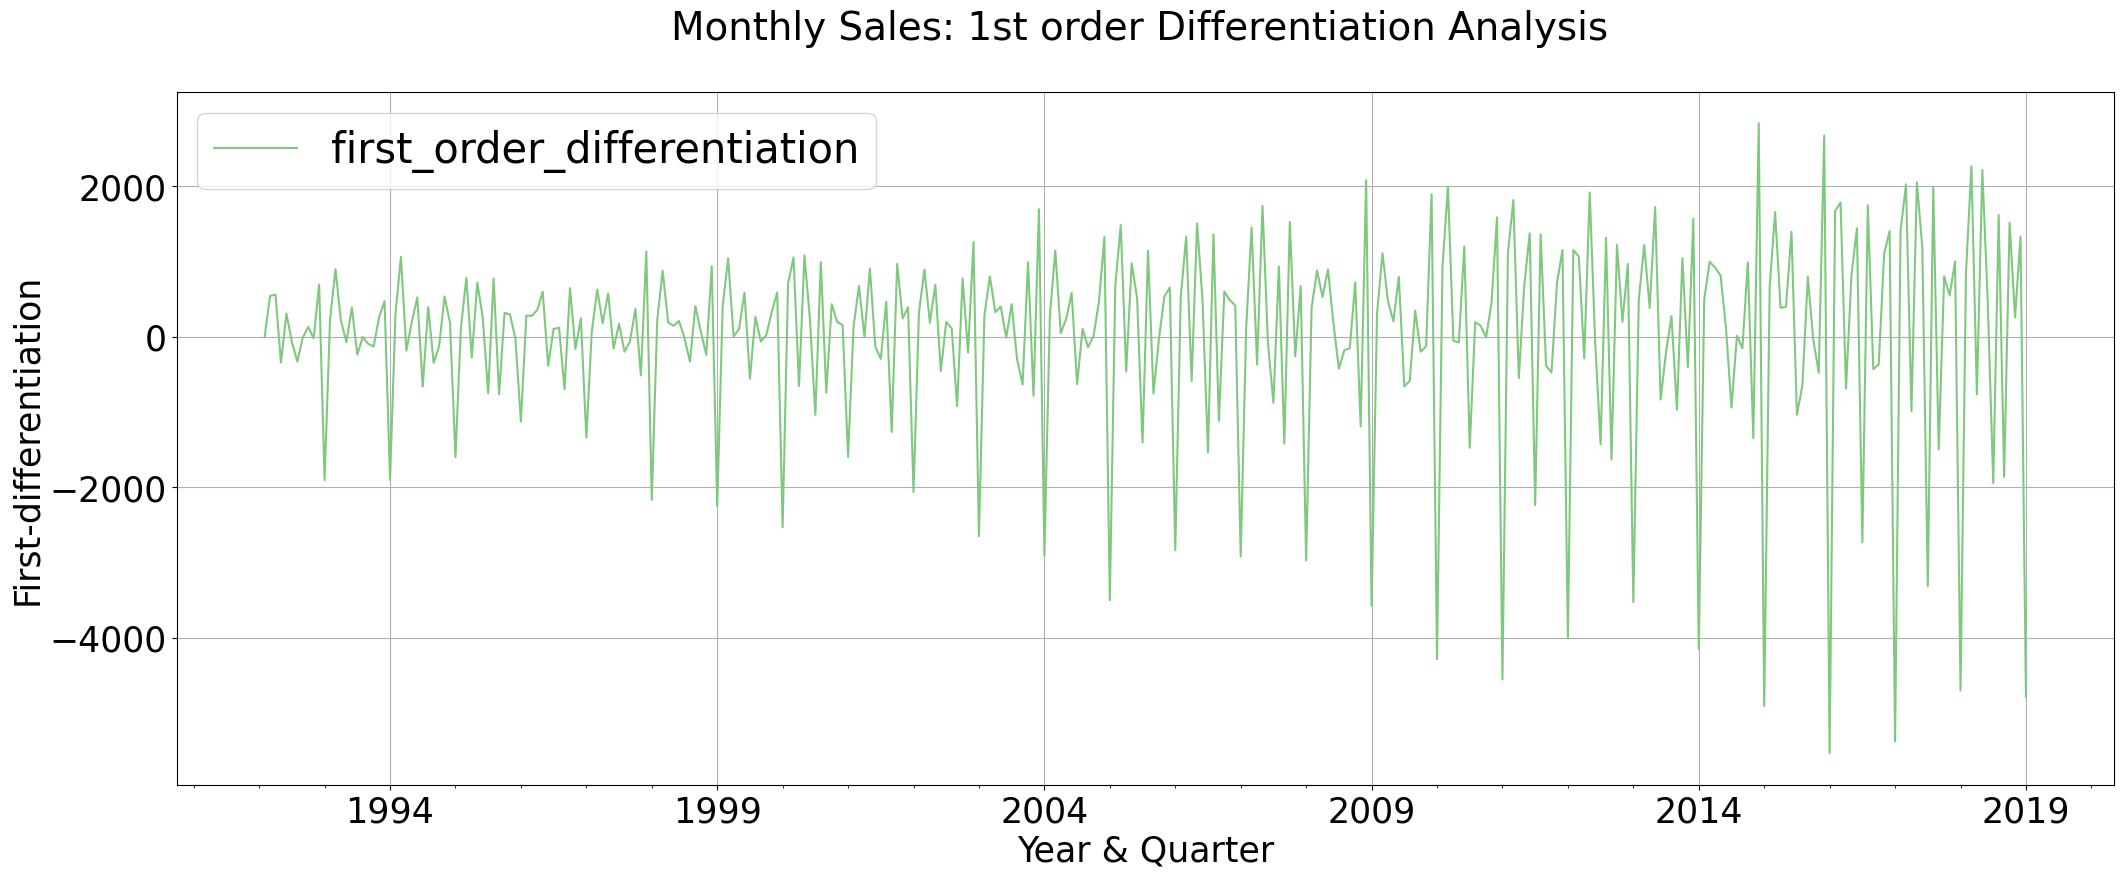

In [88]:
df["first_order_differentiation"] = st.tsa.statespace.tools.diff(df["Sales"], k_diff = 1)

ax =  df["first_order_differentiation"].plot(legend =True, table = False, grid = True, subplots = False, figsize =(25,9), fontsize = 25, colormap = 'Accent', linestyle='-', stacked=False)
plt.ylabel('First-differentiation',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.title('Monthly Sales: 1st order Differentiation Analysis \n',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
plt.legend(loc='upper left', fontsize = 30)
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")
ax.autoscale(enable=True, axis='x', tight=False)

In [66]:
# Check for stationarity. OK!!
adf_test(df["first_order_differentiation"], title = "Automated ADF Test for Stationarity")

Augmented Dickey-Fuller Test: Automated ADF Test for Stationarity
ADF test statistic       -4.365960
p-value                   0.000341
# lags used              13.000000
# observations          310.000000
critical value (1%)      -3.451622
critical value (5%)      -2.870909
critical value (10%)     -2.571762
Strong evidence against the null hypothesis
Reject the null hypothesis
Data has no unit root and is stationary


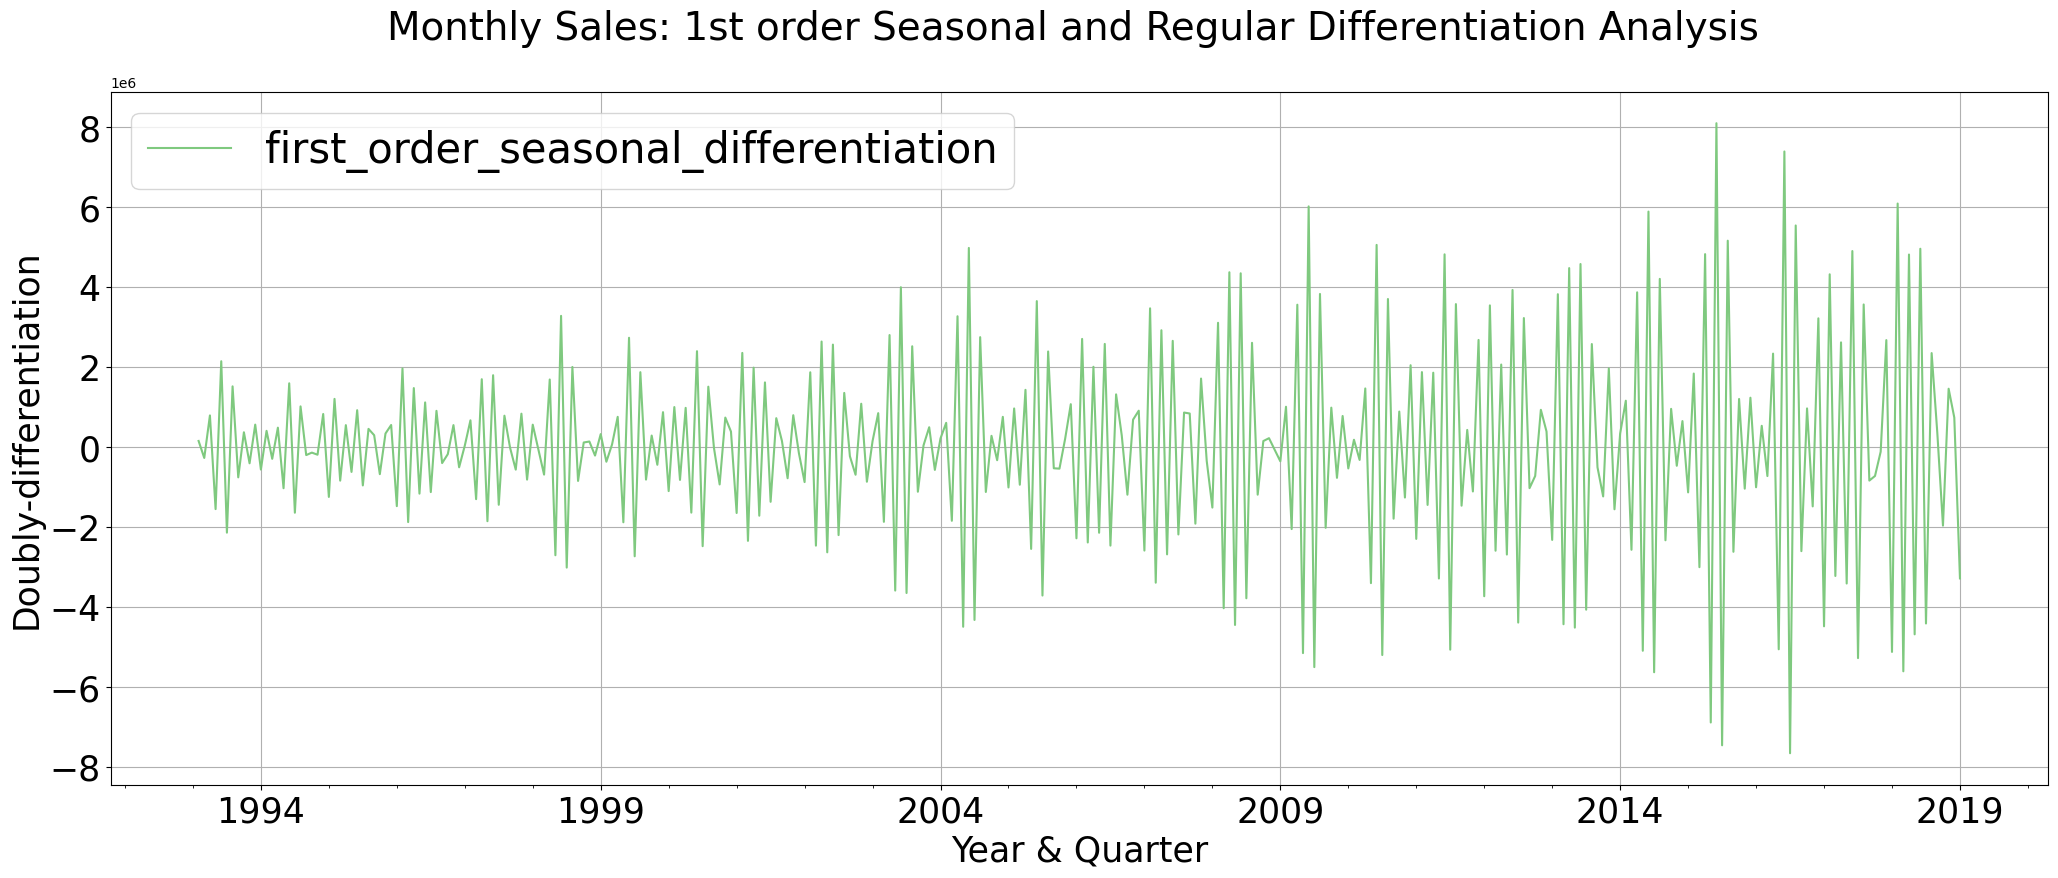

In [89]:
# What about subtracting 12-month periodicity? Nice!! Peaks appear much more randomly.
df["first_order_seasonal_differentiation"] = st.tsa.statespace.tools.diff(df["first_order_differentiation"], k_diff = 12)

ax =  df["first_order_seasonal_differentiation"].plot(legend =True, table = False, grid = True, subplots = False, figsize =(25,9), fontsize = 25, colormap = 'Accent', linestyle='-', stacked=False)
plt.ylabel('Doubly-differentiation',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.xlabel('Year & Quarter',horizontalalignment="center",fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.title('Monthly Sales: 1st order Seasonal and Regular Differentiation Analysis \n',horizontalalignment="center", fontstyle = "normal", fontsize = 28, fontfamily = "sans-serif")
plt.legend(loc='upper left', fontsize = 30)
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")
ax.autoscale(enable=True, axis='x', tight=False)

In [68]:
# Last check for stationarity to doubly-differentiated timeseries. EVEN BETTER!!
adf_test(df["first_order_seasonal_differentiation"], title = "Automated ADF Test for Stationarity")

Augmented Dickey-Fuller Test: Automated ADF Test for Stationarity
ADF test statistic      -23.401364
p-value                   0.000000
# lags used              16.000000
# observations          295.000000
critical value (1%)      -3.452713
critical value (5%)      -2.871388
critical value (10%)     -2.572017
Strong evidence against the null hypothesis
Reject the null hypothesis
Data has no unit root and is stationary


** ARIMA models **

* Theory:
    1. An autoregressive model of order p, AM(p), for a timeseries follows:
    x_t = c + f_1 x_t-1 + f_2 x_t-2 + ... + f_p x_t-p + eps_t
   where eps_t is white noise.
    2. A moving average model of order q, MA(q), for a timeseries follows:
    x_t = c + eps_t + g_1 eps_t-1 + g_2 eps_t-2 + ... + g_q eps_t-q
   where eps_t is white noise and eps_t-k are forecast erros in a regression-like model.
    3. A "non-seasonal" ARIMA(p,d,q) model for a timeseries follows:
    y_t = c + f_1 y_t-1 + ... + f_p y_t-p + g_1 eps_t-1 + ... + g_q eps_t-q + eps_t
   where y_t = x_t^(d) = (1-L)^d x_t is the "d"-differentiated series.
        - Equivalent to:
        (1 - f_1 L - ... - f_p B^p)(1-L)^d x_t = c + (1 + g_1 L + ... + g_q L^q)eps_t
        or simply: AR(p)(1-L)^d x_t = MA(q)

* Notes:
    1. Coefficients are estimated by maximum (log) likelihood estimation (MLE).
    2. Useful to determine the order of p and q is to minimize the Akaike’s Info. Criterion (AIC): AIC = -2 log(L) + 2(p + q + s + 1), where s = 1 if c!=0 (s=0 if c=0).
    3. Corrected AIC (AICc) is defined in https://otexts.com/fpp2/arima-estimation.html

* Examples:
    1. ARIMA(0,0,0) --> x_t = c + eps_t --> white noise.
    2. ARIMA(0,1,0) w/ c=0 --> x_t' = eps_t --> x_t = x_t-1 + eps_t --> random walk.
    3. ARIMA(0,1,0) w/ c!=0 --> random walk with drift.
    4. ARIMA(p,0,0) = AR(p) or ARIMA(0,0,q) = AM(q).

* Observations:
    1. If c=0 and d=0, the long-term forecasts will go to zero.
    2. If c=0 and d=1, the long-term forecasts will go to a non-zero constant.
    3. If c=0 and d=2, the long-term forecasts will follow a straight line.
    4. If c!=0 and d=0, the long-term forecasts will go to the mean of the data.
    5. If c!=0 and d=1, the long-term forecasts will follow a straight line.
    6. If c!=0 and d=2, the long-term forecasts will follow a quadratic trend.

* Results:
    1. The higher the value of d, the more rapidly the prediction intervals increase in size. If d=0, the forecast std. will go to the historical std.
    2. If data follows ARIMA(p,d,0):
       - the ACF is exponentially decaying or sinusoidal;
       - there is a significant spike at lag p in the PACF, but none beyond lag p.
    3. If data follows ARIMA(0,d,q):
       - the PACF is exponentially decaying or sinusoidal;
       - there is a significant spike at lag q in the ACF, but none beyond lag q.

* Generalization for seasonal (S) time-series (SARIMA model):
    1. Identify seasonality period m = number of observations per year.
    2. Extend the ARIMA(p,d,q)(P,D,Q)[m] model for some (P,D,Q), besides (p,d,q):
       AR(Q)AR(p)(1-L)^D(1-L)^d x_t = MA(Q)MA(q)

* From our previous Diffentiation and ACF and PACF analysis, m=12, d=1, D=1, p ~ 3-6 months ( 1 or 2 quarters), P ~ 1 and at most 2 years (12 or 24 months).

In [116]:
# Let's use auto_arima to find orders:
print(pmdarima.auto_arima(df["Sales"], seasonal = True, m=12, error_action = "ignore").summary())

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  325
Model:             SARIMAX(3, 1, 2)x(2, 1, 2, 12)   Log Likelihood               -2212.240
Date:                            Tue, 10 Oct 2023   AIC                           4444.480
Time:                                    23:08:18   BIC                           4481.910
Sample:                                01-01-1992   HQIC                          4459.440
                                     - 01-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0776      0.221     -0.350      0.726      -0.512       0.356
ar.L2          0.0948      0.089   

* In summary:
    - Best result: SARIMAX(3, 1, 2)x(2, 1, 2)[12]
    - The Ljung-Box test (p_val = 0.68) shows that the residuals (errors) have no remaining autocorrelations.

In [98]:
"""
Revalidate SARIMA orders using 'stepwise' option (Hyndman and Khandakar algorithm, https://otexts.com/fpp2/arima-r.html), instead of trying sequentially or randomly. Fit calls scipy.optimize (default lbfgs).

Doc: https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html
Options:
- out_of_sample_size=365 (if you want to use the last 365 days as test sample). Forecasting will in any case start after this set. Use 'mse' for 'scoring'.
- d=None, D=none: use kpss to determine diff. orders.
"""

stepwise_fit = pmdarima.auto_arima(df["Sales"], m=12, d=1, D=1, start_p=3, max_p=6, start_P=1, max_P=3, max_q=5, max_Q=5, seasonal=True, trace=True, suppress_warnings=True, stepwise=True) # error_action='ignore',

Performing stepwise search to minimize aic
 ARIMA(3,1,2)(1,1,1)[12]             : AIC=4506.197, Time=8.36 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=4868.181, Time=0.07 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=4731.674, Time=0.22 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=4629.449, Time=1.05 sec
 ARIMA(3,1,2)(0,1,1)[12]             : AIC=4520.022, Time=2.18 sec
 ARIMA(3,1,2)(1,1,0)[12]             : AIC=4528.781, Time=2.51 sec
 ARIMA(3,1,2)(2,1,1)[12]             : AIC=4491.408, Time=21.47 sec
 ARIMA(3,1,2)(2,1,0)[12]             : AIC=4514.299, Time=35.35 sec
 ARIMA(3,1,2)(3,1,1)[12]             : AIC=4473.673, Time=26.33 sec
 ARIMA(3,1,2)(3,1,0)[12]             : AIC=4493.748, Time=9.91 sec
 ARIMA(3,1,2)(3,1,2)[12]             : AIC=4450.776, Time=13.52 sec
 ARIMA(3,1,2)(2,1,2)[12]             : AIC=4444.480, Time=8.65 sec
 ARIMA(3,1,2)(1,1,2)[12]             : AIC=4499.385, Time=6.49 sec
 ARIMA(3,1,2)(2,1,3)[12]             : AIC=4449.941, Time=12.26 sec
 ARIMA(3,1,2)(

* Let's check performance of the model.
* Divide train/test datasets. Test are final points.

In [133]:
# Training set:
train_percentage = 0.93
train_npoints = int(len(df)*train_percentage)
print("Training with ", str(train_npoints), " points.")
df_train = df.iloc[:train_npoints,:1] #just take first column ('Sales')
df_train.tail(2)

Training with  302  points.


,Sales
Month,
2017-01-01,9043
2017-02-01,10452


In [135]:
# Testing set:
df_test = df.iloc[train_npoints:, :1]
print("Testing with the last ", str(df_test.shape[0]), " points.")
df_test.head(2)

Testing with the last  23  points.


,Sales
Month,
2017-03-01,12481
2017-04-01,11491


In [201]:
# Obtain SARIMAX model with found orders using train sample:
# Doc:
# https://www.statsmodels.org/stable/examples/notebooks/generated/statespace_sarimax_stata.html
# https://www.statsmodels.org/dev/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
# https://www.statsmodels.org/dev/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.fit.html

fitted_SARIMA_model = st.tsa.statespace.sarimax.SARIMAX(df_train["Sales"], order =(3,1,2), seasonal_order = (2,1,2,12))

#increasing maxiter to converge.
results = fitted_SARIMA_model.fit(maxiter=150)

/usr/local/anaconda3/envs/pythonc310Project/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/anaconda3/envs/pythonc310Project/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           10     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.34502D+00    |proj g|=  4.08240D+00


 This problem is unconstrained.



At iterate    5    f=  6.81118D+00    |proj g|=  6.12505D-02

At iterate   10    f=  6.78855D+00    |proj g|=  7.83403D-03

At iterate   15    f=  6.78596D+00    |proj g|=  2.29020D-02

At iterate   20    f=  6.78552D+00    |proj g|=  2.96191D-03

At iterate   25    f=  6.78439D+00    |proj g|=  1.07395D-02

At iterate   30    f=  6.78360D+00    |proj g|=  2.99956D-03

At iterate   35    f=  6.78355D+00    |proj g|=  2.20609D-03

At iterate   40    f=  6.78348D+00    |proj g|=  3.90861D-03

At iterate   45    f=  6.78205D+00    |proj g|=  2.23741D-02

At iterate   50    f=  6.77493D+00    |proj g|=  4.60380D-02

At iterate   55    f=  6.76685D+00    |proj g|=  1.05915D-02

At iterate   60    f=  6.76578D+00    |proj g|=  8.58115D-03

At iterate   65    f=  6.76314D+00    |proj g|=  3.19123D-02

At iterate   70    f=  6.76088D+00    |proj g|=  1.79392D-02

At iterate   75    f=  6.75979D+00    |proj g|=  6.26668D-03

At iterate   80    f=  6.75957D+00    |proj g|=  1.21612D-03

At iter

* Note that fit converged in the end! The Ljung-Box test improved to p_val = 0.81.

In [202]:
print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                  302
Model:             SARIMAX(3, 1, 2)x(2, 1, 2, 12)   Log Likelihood               -2039.091
Date:                            Wed, 11 Oct 2023   AIC                           4098.182
Time:                                    02:25:13   BIC                           4134.846
Sample:                                01-01-1992   HQIC                          4112.873
                                     - 02-01-2017                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1279      0.186     -0.688      0.491      -0.492       0.236
ar.L2          0.1228      0.078   

In [203]:
# Predict test points:
test_SARIMA_predictions = results.predict(start=df_train.shape[0], end=(df.shape[0] - 1)).rename('SARIMA-Predicted Sales')

# Print MSE:
mse = np.sqrt(sklearn.metrics.mean_squared_error(df_test, test_SARIMA_predictions))
print("Root Mean Squared Error = ", str(round(mse,2)))

# Include actual values to compare with predictions:
test_SARIMA_predictions = pd.DataFrame(test_SARIMA_predictions).round(decimals=1).join(df_test['Sales'])

# Include +/- MSE band in test_SARIMA_predictions:
test_SARIMA_predictions["Predicted Inbound Variance"] = (test_SARIMA_predictions["SARIMA-Predicted Sales"]-mse).round(decimals=1)
test_SARIMA_predictions["Predicted Outbound Variance"]= (test_SARIMA_predictions["SARIMA-Predicted Sales"]+mse).round(decimals=1)

test_SARIMA_predictions

Root Mean Squared Error =  355.11


,SARIMA-Predicted Sales,Sales,Predicted Inbound Variance,Predicted Outbound Variance
2017-03-01,12332.3,12481,11977.2,12687.4
2017-04-01,11611.7,11491,11256.6,11966.8
2017-05-01,13221.5,13545,12866.4,13576.6
2017-06-01,13846.6,14730,13491.5,14201.7
2017-07-01,11413.1,11416,11058.0,11768.2
2017-08-01,13536.6,13402,13181.5,13891.7
2017-09-01,12356.3,11907,12001.2,12711.4
2017-10-01,12670.3,12711,12315.2,13025.4
2017-11-01,13558.7,13261,13203.6,13913.8
2017-12-01,14605.4,14265,14250.3,14960.5


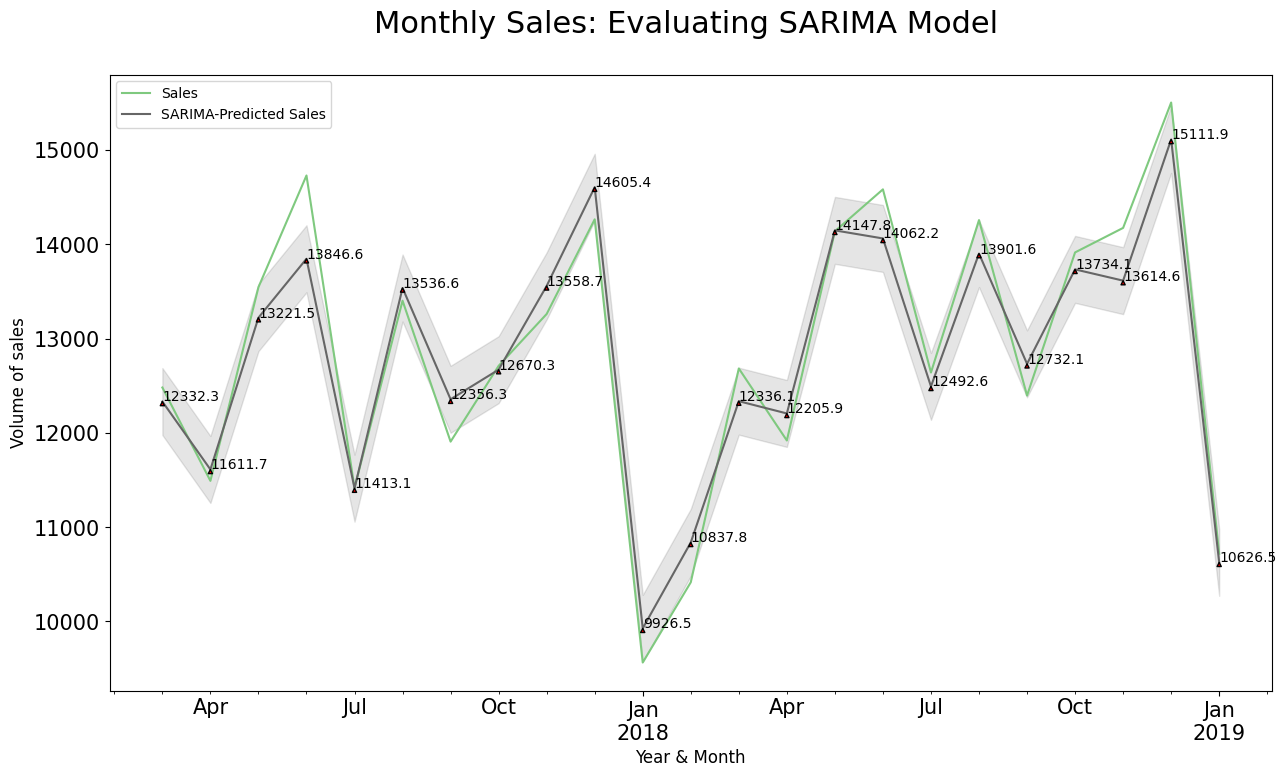

In [207]:
#Plot the Graph:

ax = test_SARIMA_predictions[["Sales", "SARIMA-Predicted Sales"]].plot(title = 'Monthly Sales: Evaluating SARIMA Model', legend =True, table = False, grid = False, subplots = False, figsize =(15,8), colormap = 'Accent', fontsize = 15, linestyle='-', stacked=False)

ax.fill_between(test_SARIMA_predictions.index, test_SARIMA_predictions['Predicted Inbound Variance'], test_SARIMA_predictions['Predicted Outbound Variance'], color='k', alpha=0.1);

for i in np.arange(0,len(test_SARIMA_predictions)):
    ax.annotate(str(test_SARIMA_predictions["SARIMA-Predicted Sales"][i]),
                xy=(test_SARIMA_predictions.index[i], test_SARIMA_predictions["SARIMA-Predicted Sales"][i]),
                xycoords='data',
                xytext=(test_SARIMA_predictions.index[i],test_SARIMA_predictions["SARIMA-Predicted Sales"][i]+5),
                arrowprops=dict(facecolor='r',headwidth=3,headlength=3 )) #shrink=0.05

#Configure x and y labels:
plt.ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")
plt.xlabel('Year & Month',horizontalalignment="center",fontstyle = "normal", fontsize = "large", fontfamily = "sans-serif")

#Set up title, legends and theme:
plt.title('Monthly Sales: Evaluating SARIMA Model \n',horizontalalignment="center", fontstyle = "normal", fontsize = "22", fontfamily = "sans-serif")
plt.legend(loc='upper left', fontsize = "medium")
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")
#plt.style.use(['classic'])
ax.autoscale(enable=True, axis='x', tight=False)

* Summary of steps before forecasting "non-seasonal" time-series:
    1. Plot the data and identify any unusual observations.
    2. If necessary, transform the data (e.g., log, Box-Cox) to stabilise the variance.
    3. If the data are non-stationary, take first differences until the data are stationary.
    4. Examine the ACF/PACF: Is an ARIMA(0,d,q) or ARIMA(p,d,0) model appropiate?
    5. Choose best model by minimizing AICc / check performance.
    6. Check residuals (ACF of errors, Ljung-Box Q-test), should look like white noise. If not, modify model.
    7. Forecast!

In [205]:
# To forecast, let's re-train the forecasting model on the full dataset:
final_model = st.tsa.statespace.sarimax.SARIMAX(df["Sales"], order =(3,1,2), seasonal_order = (2,1,2,12))
SARIMAfit = final_model.fit(maxiter=150)

/usr/local/anaconda3/envs/pythonc310Project/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/anaconda3/envs/pythonc310Project/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           10     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.18793D+00    |proj g|=  3.69965D+00

At iterate    5    f=  6.86401D+00    |proj g|=  6.29293D-02

At iterate   10    f=  6.84310D+00    |proj g|=  1.64167D-02

At iterate   15    f=  6.83887D+00    |proj g|=  2.23672D-02

At iterate   20    f=  6.83776D+00    |proj g|=  4.95119D-03

At iterate   25    f=  6.83743D+00    |proj g|=  4.28283D-03

At iterate   30    f=  6.83536D+00    |proj g|=  3.47782D-03

At iterate   35    f=  6.83505D+00    |proj g|=  9.25387D-04

At iterate   40    f=  6.83501D+00    |proj g|=  1.22850D-03

At iterate   45    f=  6.83403D+00    |proj g|=  2.74322D-02

At iterate   50    f=  6.80689D+00    |proj g|=  2.53440D-02

At iterate   55    f=  6.80087D+00    |proj g|=  2.24944D-02

At iterate   60    f=  6.79939D+00    |proj g|=  3.71494D-03

At iterate   65    f=  6.7

In [220]:
# Now let's forecast the next 24 months (feb 2019 - jan 2021):
#forecast_SARIMA_predictions = SARIMAfit.predict(start = len(df), end = len(df)+23, dynamic = False, typ = 'levels').rename('Forecast')
# etc. etc., as we did before.

# Instead, I'm going to use .get_forecast to obtain correct confidence intervals:
# https://www.statsmodels.org/dev/examples/notebooks/generated/statespace_forecasting.html#Prediction-vs-Forecasting

forecast_SARIMA_predictions = SARIMAfit.get_forecast(steps=24)
print(forecast_SARIMA_predictions.summary_frame(alpha=0.05)) # here alpha is CL.

Sales               mean     mean_se  mean_ci_lower  mean_ci_upper
2019-02-01  11351.025713  276.071376   10809.935759   11892.115666
2019-03-01  13172.919627  281.026343   12622.118116   13723.721139
2019-04-01  13002.300013  286.245141   12441.269846   13563.330179
2019-05-01  14636.741633  310.599386   14027.978022   15245.505244
2019-06-01  15056.337471  313.163113   14442.549048   15670.125893
2019-07-01  13770.472151  317.500679   13148.182255   14392.762048
2019-08-01  14390.434598  323.892451   13755.617058   15025.252137
2019-09-01  13419.510592  325.995588   12780.570981   14058.450204
2019-10-01  14710.850183  328.919242   14066.180315   15355.520050
2019-11-01  14269.585660  331.838374   13619.194398   14919.976922
2019-12-01  16381.871401  333.710647   15727.810552   17035.932251
2020-01-01  11168.638692  335.853849   10510.377245   11826.900140
2020-02-01  12012.138273  421.727788   11185.566997   12838.709549
2020-03-01  13826.244370  428.468351   12986.461833   14666.02

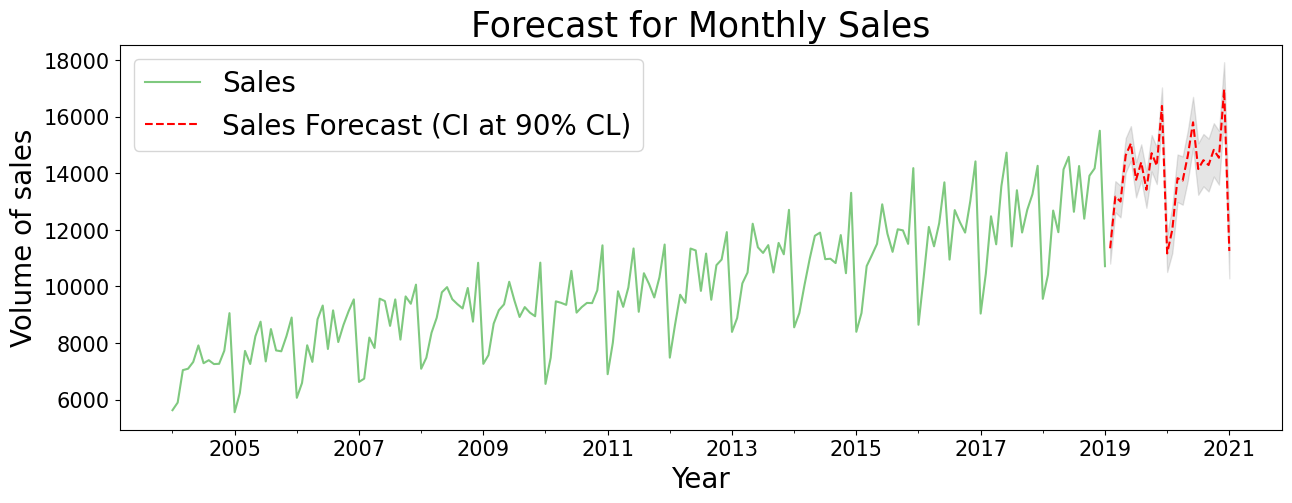

In [241]:
fig, ax = plt.subplots(figsize=(15, 5))

# Plot the data (here we are sub-setting it to get a better look at the forecasts)
df[df.index.year>=2004]["Sales"].plot(ax=ax, legend =True, table = False, grid = True, fontsize = 15, colormap = 'Accent', linestyle='-', stacked=False)

# Construct the forecasts
fcast = forecast_SARIMA_predictions.summary_frame(alpha=0.05) #here alpha is CL.
fcast['mean'].rename('Sales Forecast (CI at 90% CL)').plot(ax=ax, style='r--')
ax.fill_between(fcast.index, fcast['mean_ci_lower'], fcast['mean_ci_upper'], color='k', alpha=0.1); #here alpha is transparency

plt.ylabel('Volume of sales',horizontalalignment="center",fontstyle = "normal", fontsize = 20, fontfamily = "sans-serif")
plt.xlabel('Year',horizontalalignment="center",fontstyle = "normal", fontsize = 20, fontfamily = "sans-serif")
plt.title('Forecast for Monthly Sales',horizontalalignment="center", fontstyle = "normal", fontsize = 25, fontfamily = "sans-serif")
plt.legend(loc='upper left', fontsize = 20)
plt.xticks(rotation=0, horizontalalignment="center")
plt.yticks(rotation=0, horizontalalignment="right")
ax.autoscale(enable=True, axis='x', tight=False)